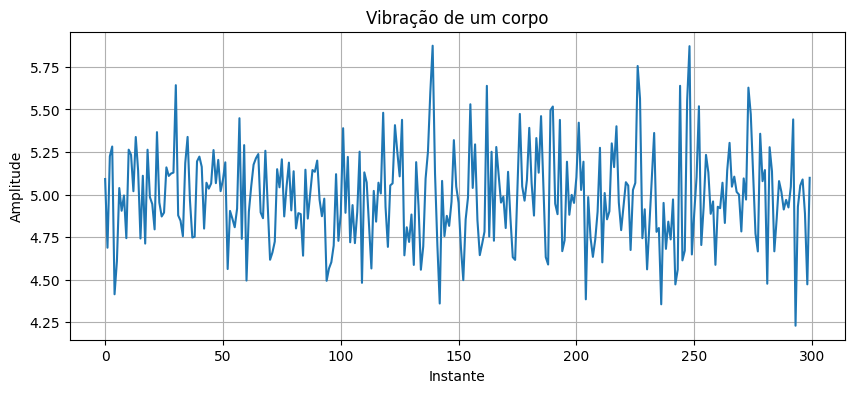

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
vibracao = rng.normal(loc=5, scale=0.3, size = 300)
plt.figure(figsize=(10,4))
plt.plot(vibracao)
plt.xlabel("Instante")
plt.ylabel("Amplitude")
plt.title("Vibração de um corpo")
plt.grid(True)
plt.show()

In [ ]:
!pip install cesium

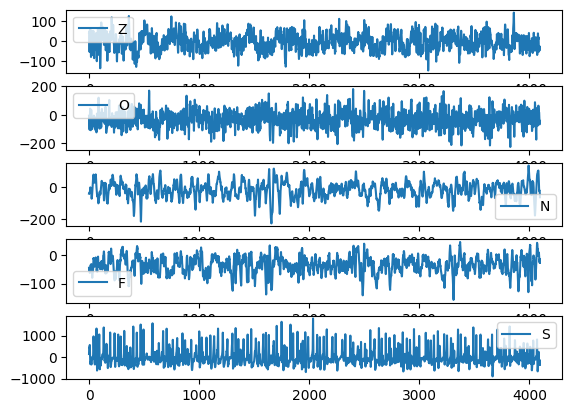

In [ ]:
from cesium import datasets

eeg = datasets.fetch_andrzejak()

plt.subplot(5,1,1)
plt.plot(eeg['measurements'][0])
plt.legend(eeg['classes'][0])

plt.subplot(5,1,2)
plt.plot(eeg['measurements'][100])
plt.legend(eeg['classes'][100])

plt.subplot(5,1,3)
plt.plot(eeg['measurements'][200])
plt.legend(eeg['classes'][200])

plt.subplot(5,1,4)
plt.plot(eeg['measurements'][300])
plt.legend(eeg['classes'][300])

plt.subplot(5,1,5)
plt.plot(eeg['measurements'][400])
plt.legend(eeg['classes'][400])

In [ ]:
from cesium.featurize import featurize_time_series as ft

feature_to_use = ['amplitude',
                  "percent_beyond_1_std",
                  "percent_close_to_median",
                  "skew",
                  "max_slope"]

fset_cesium = ft(times =  eeg['times'],
                 values = eeg['measurements'],
                 features_to_use = feature_to_use,
                 )

In [ ]:
fset_cesium["y"] = eeg['classes']
fset_cesium.head()

feature,amplitude,percent_beyond_1_std,percent_close_to_median,skew,max_slope,y
channel,0,0,0,0,0,
0,143.5,0.327313,0.505004,0.032805,11107.796610,Z
1,211.5,0.290212,0.640469,-0.092715,20653.559322,Z
2,165.0,0.302660,0.515987,-0.004100,13537.627119,Z
3,171.5,0.300952,0.541128,0.063678,17008.813559,Z
4,170.0,0.305101,0.566268,0.142753,13016.949153,Z


In [ ]:
np.std(eeg["measurements"][0])

np.float64(40.41100040099819)

In [ ]:
np.mean(eeg["measurements"][0])

np.float64(-4.1320478398828415)

In [ ]:
samples_ts = eeg['measurements'][0]
sz = len(samples_ts)

In [ ]:
lb =-4.13 - 40.41
ub = -4.13 + 40.41

quals = [i for i in range(sz) if samples_ts[i] < lb or samples_ts[i] > ub]

len(quals)/len(samples_ts)

0.3273126678057115

In [ ]:
from sklearn.model_selection import train_test_split

X = fset_cesium.drop(columns = ["y"])
y = fset_cesium["y"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

/tmp/ipykernel_1953/4014122303.py:3: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  X = fset_cesium.drop(columns = ["y"])


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(
    n_estimators=75,
    max_depth=10,
    min_samples_split=2,
    random_state = 42,
)

rf_clf.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, n_estimators=75)

In [ ]:
rf_clf.score(X_test, y_test)

0.69